##CNN,Xgboost, MLP, RANDOM FOREST

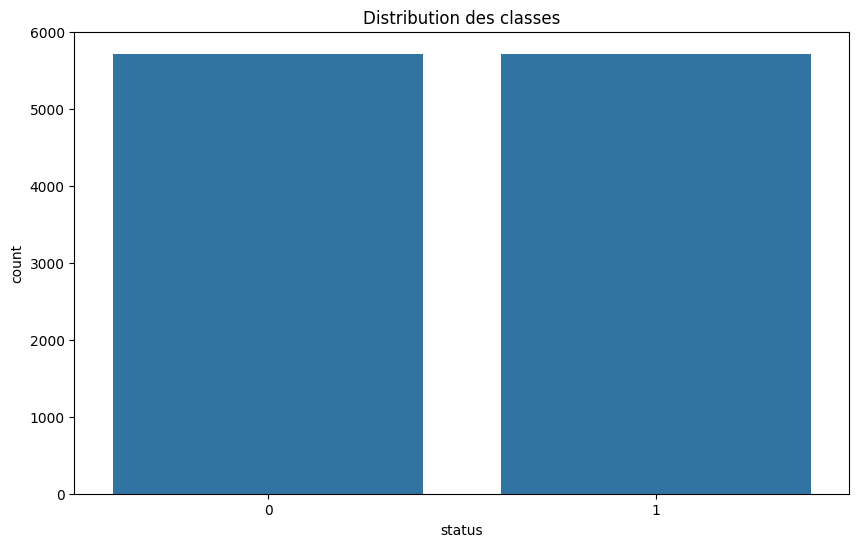

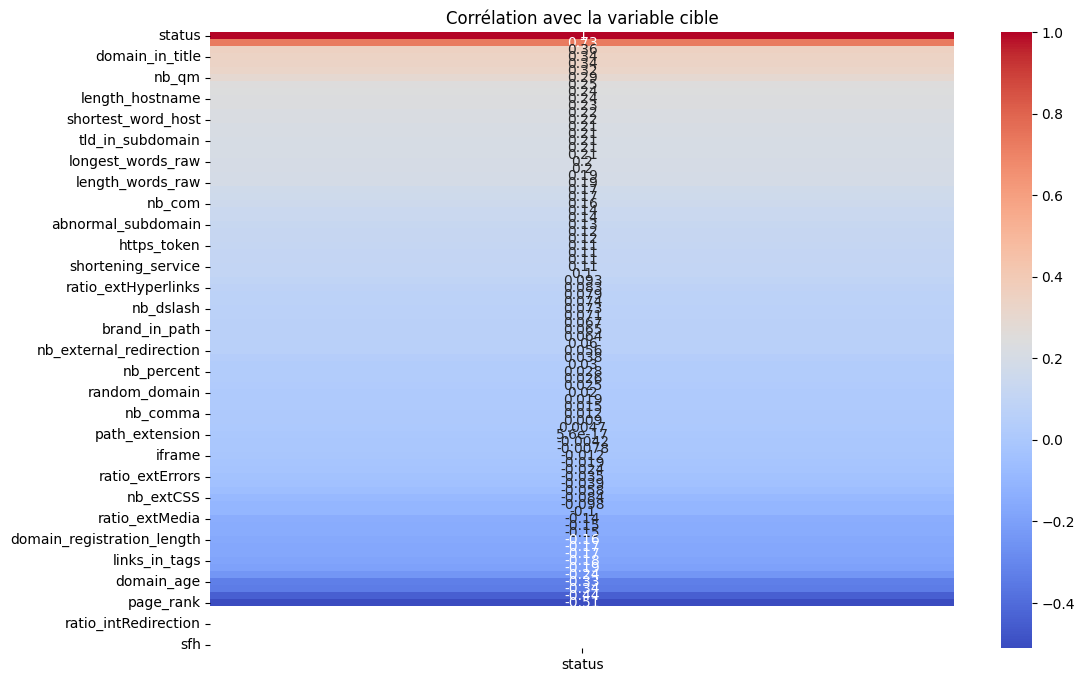

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


mlp entraîné.


cnn entraîné.
xgb entraîné.
rf entraîné.
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step

--- Rapport de classification pour chaque modèle ---
MLP:
              precision    recall  f1-score   support

           0       0.95      0.97      0.96      1143
           1       0.97      0.94      0.96      1143

    accuracy                           0.96      2286
   macro avg       0.96      0.96      0.96      2286
weighted avg       0.96      0.96      0.96      2286

CNN:
              precision    recall  f1-score   support

           0       0.96      0.94      0.95      1143
           1       0.95      0.96      0.95      1143

    accuracy                           0.95      2286
   macro avg       0.95      0.95      0.95      2286
weighted avg       0.95      0.95      0.95      2286

XGBoost:
              precision    recall  f1-score   support

           0       0.97      0.96      0.97      1143
           1       0.96      0.97      0.97  

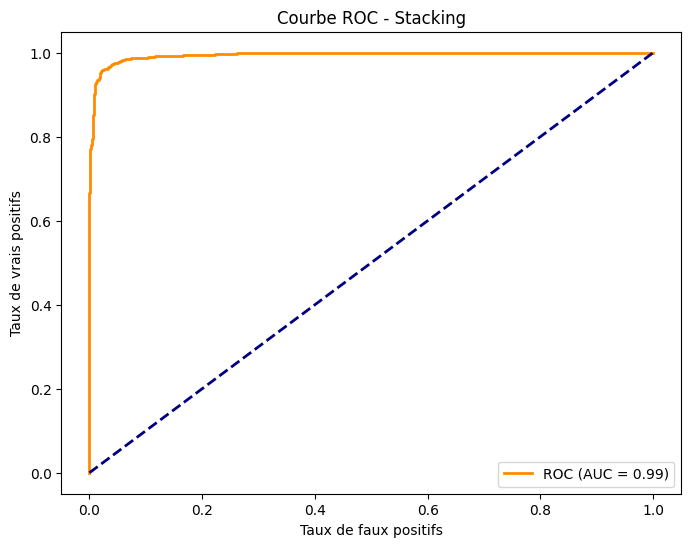

In [ ]:
import concurrent.futures
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement et Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

# Modèles deep learning avec Keras
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout, Conv1D, MaxPooling1D, Flatten, LSTM
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Modèles scikit-learn et XGBoost
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

# Méta-modèle (stacking)
from sklearn.linear_model import LogisticRegression

# ------------------------
# Chargement et préparation des données
# ------------------------
df = pd.read_csv("dataset_phishing.csv")
df = df.drop(columns=['url'])  # Suppression de la colonne non pertinente
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})  # Encodage de la variable cible

# Visualisation exploratoire (optionnel)
plt.figure(figsize=(10, 6))
sns.countplot(x='status', data=df)
plt.title('Distribution des classes')
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr()[['status']].sort_values('status', ascending=False),
            annot=True, cmap='coolwarm')
plt.title('Corrélation avec la variable cible')
plt.show()

X = df.drop(columns=['status']).values
y = df['status'].values

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# Pour les modèles CNN et LSTM, on ajoute une dimension canal
X_train_3d = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test_3d  = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

epochs = 100
batch_size = 64

# ------------------------
# Définition des fonctions d'entraînement pour chaque modèle
# ------------------------

def train_mlp():
    def build_mlp(input_shape):
        model = Sequential([
            Dense(128, activation='relu', input_shape=(input_shape,)),
            BatchNormalization(),
            Dropout(0.3),
            Dense(64, activation='relu'),
            BatchNormalization(),
            Dropout(0.3),
            Dense(32, activation='relu'),
            BatchNormalization(),
            Dropout(0.3),
            Dense(1, activation='sigmoid')
        ])
        model.compile(optimizer='adam',
                      loss='binary_crossentropy',
                      metrics=['accuracy'])
        return model

    model = build_mlp(X_train.shape[1])
    callbacks = [
        EarlyStopping(patience=10, restore_best_weights=True),
        ModelCheckpoint('mlp_best.h5', save_best_only=True)
    ]
    model.fit(X_train, y_train,
              epochs=epochs,
              batch_size=batch_size,
              validation_split=0.2,
              callbacks=callbacks,
              class_weight={0: 1, 1: 1.2},
              verbose=0)
    return model

def train_cnn():
    def build_cnn(input_shape):
        model = Sequential([
            Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=input_shape),
            MaxPooling1D(pool_size=2),
            BatchNormalization(),
            Dropout(0.3),
            Conv1D(filters=32, kernel_size=3, activation='relu'),
            MaxPooling1D(pool_size=2),
            BatchNormalization(),
            Dropout(0.3),
            Flatten(),
            Dense(64, activation='relu'),
            BatchNormalization(),
            Dropout(0.3),
            Dense(1, activation='sigmoid')
        ])
        model.compile(optimizer='adam',
                      loss='binary_crossentropy',
                      metrics=['accuracy'])
        return model

    model = build_cnn((X_train_3d.shape[1], X_train_3d.shape[2]))
    callbacks = [
        EarlyStopping(patience=10, restore_best_weights=True),
        ModelCheckpoint('cnn_best.h5', save_best_only=True)
    ]
    model.fit(X_train_3d, y_train,
              epochs=epochs,
              batch_size=batch_size,
              validation_split=0.2,
              callbacks=callbacks,
              class_weight={0: 1, 1: 1.2},
              verbose=0)
    return model



def train_xgb():
    model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
    model.fit(X_train, y_train)
    return model

def train_rf():
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)
    return model

# ------------------------
# Entraînement des modèles en parallèle
# ------------------------
models = {}
with concurrent.futures.ThreadPoolExecutor() as executor:
    futures = {
        "mlp": executor.submit(train_mlp),
        "cnn": executor.submit(train_cnn),

        "xgb": executor.submit(train_xgb),
        "rf": executor.submit(train_rf),
    }
    for name, future in futures.items():
        models[name] = future.result()
        print(f"{name} entraîné.")

# ------------------------
# Évaluation individuelle des modèles sur l'ensemble de test
# ------------------------
# Pour les modèles deep learning, on utilise X_test pour MLP et X_test_3d pour CNN et LSTM
y_pred_mlp   = (models["mlp"].predict(X_test) > 0.5).astype(int).ravel()
y_pred_cnn   = (models["cnn"].predict(X_test_3d) > 0.5).astype(int).ravel()

y_pred_xgb   = models["xgb"].predict(X_test)
y_pred_rf    = models["rf"].predict(X_test)

print("\n--- Rapport de classification pour chaque modèle ---")
print("MLP:")
print(classification_report(y_test, y_pred_mlp))
print("CNN:")
print(classification_report(y_test, y_pred_cnn))

print("XGBoost:")
print(classification_report(y_test, y_pred_xgb))
print("RandomForest:")
print(classification_report(y_test, y_pred_rf))

# ------------------------
# Stacking : création des features pour le méta-modèle
# ------------------------
# On recrée les prédictions sur l'ensemble d'entraînement pour construire le jeu de features du méta-modèle
meta_train_mlp  = models["mlp"].predict(X_train)
meta_train_cnn  = models["cnn"].predict(X_train_3d)

meta_train_xgb  = models["xgb"].predict_proba(X_train)[:, 1].reshape(-1, 1)
meta_train_rf   = models["rf"].predict_proba(X_train)[:, 1].reshape(-1, 1)

meta_features_train = np.concatenate([meta_train_mlp, meta_train_cnn,
                                      meta_train_xgb, meta_train_rf], axis=1)

# Entraînement du méta-modèle (ici une régression logistique)
meta_model = LogisticRegression()
meta_model.fit(meta_features_train, y_train)
print("\nMéta-modèle entraîné.")

# Création des features de test pour le stacking
meta_test_mlp  = models["mlp"].predict(X_test)
meta_test_cnn  = models["cnn"].predict(X_test_3d)

meta_test_xgb  = models["xgb"].predict_proba(X_test)[:, 1].reshape(-1, 1)
meta_test_rf   = models["rf"].predict_proba(X_test)[:, 1].reshape(-1, 1)

meta_features_test = np.concatenate([meta_test_mlp, meta_test_cnn,
                                     meta_test_xgb, meta_test_rf], axis=1)

y_pred_stack = meta_model.predict(meta_features_test)

print("\n--- Rapport de classification du modèle en stacking ---")
print(classification_report(y_test, y_pred_stack))

# Courbe ROC du méta-modèle
proba_stack = meta_model.predict_proba(meta_features_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, proba_stack)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Courbe ROC - Stacking')
plt.legend(loc="lower right")
plt.show()


parallel training

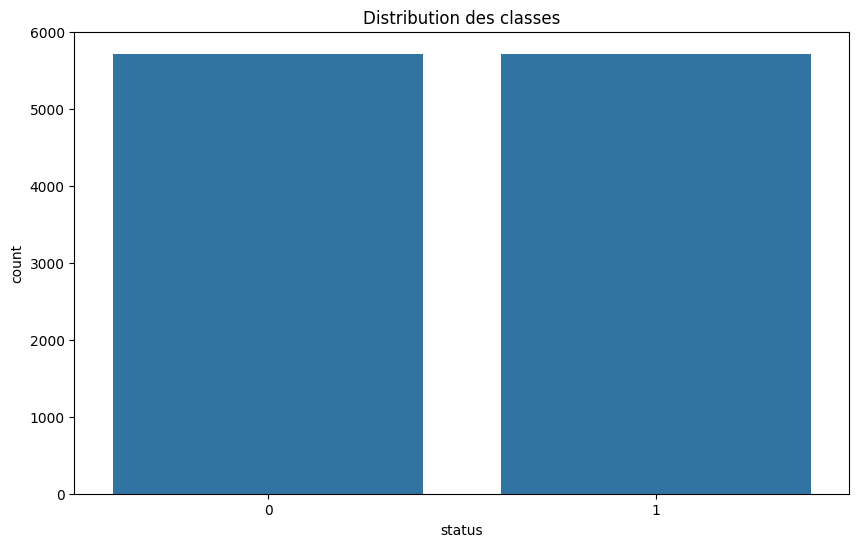

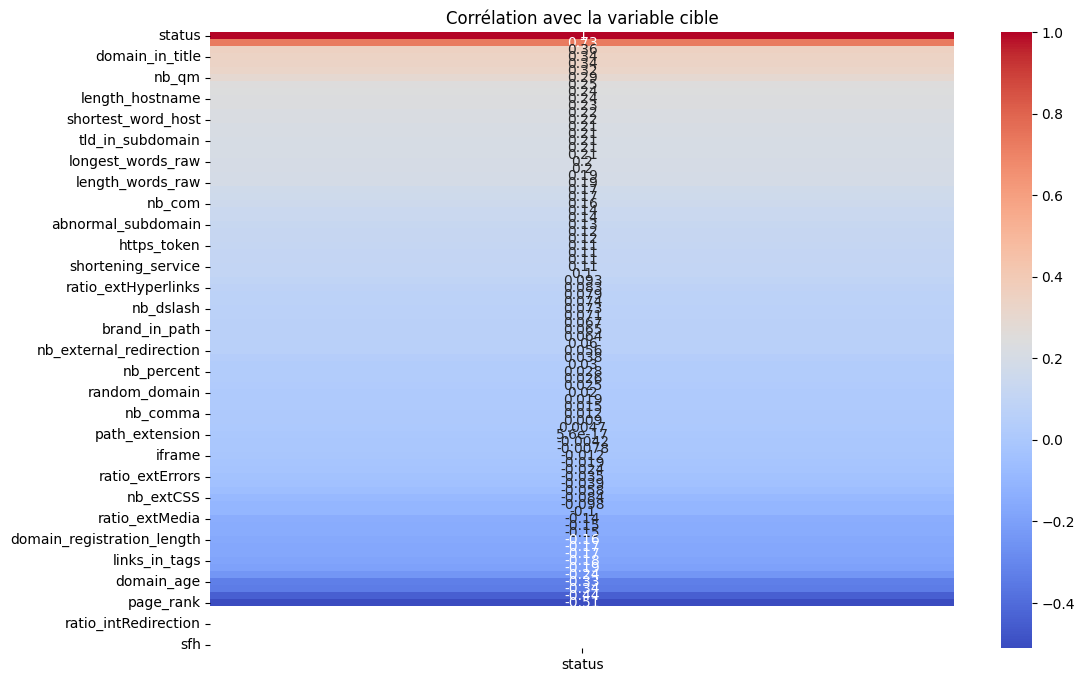

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


mlp entraîné.


cnn entraîné.


lstm entraîné.
xgb entraîné.
rf entraîné.
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step

--- Rapport de classification pour chaque modèle ---
MLP:
              precision    recall  f1-score   support

           0       0.96      0.97      0.96      1143
           1       0.97      0.95      0.96      1143

    accuracy                           0.96      2286
   macro avg       0.96      0.96      0.96      2286
weighted avg       0.96      0.96      0.96      2286

CNN:
              precision    recall  f1-score   support

           0       0.96      0.95      0.96      1143
           1       0.95      0.96      0.96      1143

    accuracy                           0.96      2286
   macro avg       0.96      0.96      0.96      2286
weighted avg       0.96      0.96      0.96      2286

LSTM:
              precision    recall  f1-score   support

           0       0.95      0.93      0.94      1143
       

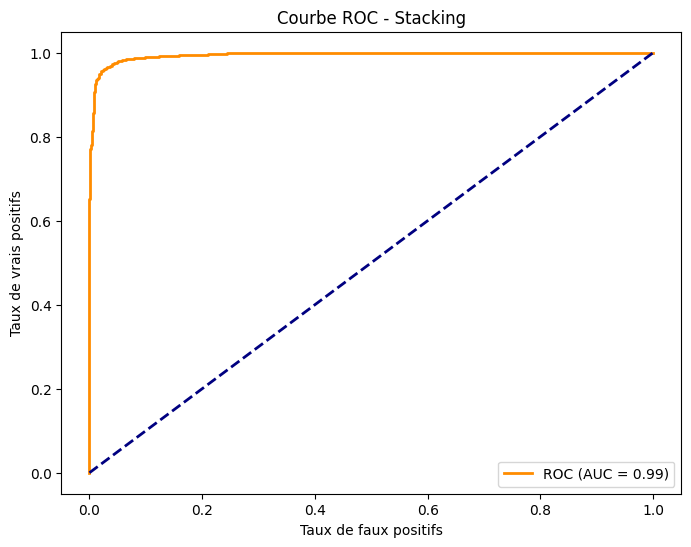

In [ ]:
import concurrent.futures
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement et Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

# Modèles deep learning avec Keras
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout, Conv1D, MaxPooling1D, Flatten, LSTM
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Modèles scikit-learn et XGBoost
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

# Méta-modèle (stacking)
from sklearn.linear_model import LogisticRegression

# ------------------------
# Chargement et préparation des données
# ------------------------
df = pd.read_csv("dataset_phishing.csv")
df = df.drop(columns=['url'])  # Suppression de la colonne non pertinente
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})  # Encodage de la variable cible

# Visualisation exploratoire (optionnel)
plt.figure(figsize=(10, 6))
sns.countplot(x='status', data=df)
plt.title('Distribution des classes')
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr()[['status']].sort_values('status', ascending=False),
            annot=True, cmap='coolwarm')
plt.title('Corrélation avec la variable cible')
plt.show()

X = df.drop(columns=['status']).values
y = df['status'].values

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# Pour les modèles CNN et LSTM, on ajoute une dimension canal
X_train_3d = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test_3d  = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

epochs = 100
batch_size = 64

# ------------------------
# Définition des fonctions d'entraînement pour chaque modèle
# ------------------------

def train_mlp():
    def build_mlp(input_shape):
        model = Sequential([
            Dense(128, activation='relu', input_shape=(input_shape,)),
            BatchNormalization(),
            Dropout(0.3),
            Dense(64, activation='relu'),
            BatchNormalization(),
            Dropout(0.3),
            Dense(32, activation='relu'),
            BatchNormalization(),
            Dropout(0.3),
            Dense(1, activation='sigmoid')
        ])
        model.compile(optimizer='adam',
                      loss='binary_crossentropy',
                      metrics=['accuracy'])
        return model

    model = build_mlp(X_train.shape[1])
    callbacks = [
        EarlyStopping(patience=10, restore_best_weights=True),
        ModelCheckpoint('mlp_best.h5', save_best_only=True)
    ]
    model.fit(X_train, y_train,
              epochs=epochs,
              batch_size=batch_size,
              validation_split=0.2,
              callbacks=callbacks,
              class_weight={0: 1, 1: 1.2},
              verbose=0)
    return model

def train_cnn():
    def build_cnn(input_shape):
        model = Sequential([
            Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=input_shape),
            MaxPooling1D(pool_size=2),
            BatchNormalization(),
            Dropout(0.3),
            Conv1D(filters=32, kernel_size=3, activation='relu'),
            MaxPooling1D(pool_size=2),
            BatchNormalization(),
            Dropout(0.3),
            Flatten(),
            Dense(64, activation='relu'),
            BatchNormalization(),
            Dropout(0.3),
            Dense(1, activation='sigmoid')
        ])
        model.compile(optimizer='adam',
                      loss='binary_crossentropy',
                      metrics=['accuracy'])
        return model

    model = build_cnn((X_train_3d.shape[1], X_train_3d.shape[2]))
    callbacks = [
        EarlyStopping(patience=10, restore_best_weights=True),
        ModelCheckpoint('cnn_best.h5', save_best_only=True)
    ]
    model.fit(X_train_3d, y_train,
              epochs=epochs,
              batch_size=batch_size,
              validation_split=0.2,
              callbacks=callbacks,
              class_weight={0: 1, 1: 1.2},
              verbose=0)
    return model

def train_lstm():
    def build_lstm(input_shape):
        model = Sequential([
            LSTM(64, activation='tanh', return_sequences=True, input_shape=input_shape),
            Dropout(0.3),
            LSTM(32, activation='tanh'),
            Dropout(0.3),
            Dense(32, activation='relu'),
            Dropout(0.3),
            Dense(1, activation='sigmoid')
        ])
        model.compile(optimizer='adam',
                      loss='binary_crossentropy',
                      metrics=['accuracy'])
        return model

    model = build_lstm((X_train_3d.shape[1], X_train_3d.shape[2]))
    callbacks = [
        EarlyStopping(patience=10, restore_best_weights=True),
        ModelCheckpoint('lstm_best.h5', save_best_only=True)
    ]
    model.fit(X_train_3d, y_train,
              epochs=epochs,
              batch_size=batch_size,
              validation_split=0.2,
              callbacks=callbacks,
              class_weight={0: 1, 1: 1.2},
              verbose=0)
    return model

def train_xgb():
    model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
    model.fit(X_train, y_train)
    return model

def train_rf():
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)
    return model

# ------------------------
# Entraînement des modèles en parallèle
# ------------------------
models = {}
with concurrent.futures.ThreadPoolExecutor() as executor:
    futures = {
        "mlp": executor.submit(train_mlp),
        "cnn": executor.submit(train_cnn),
        "lstm": executor.submit(train_lstm),
        "xgb": executor.submit(train_xgb),
        "rf": executor.submit(train_rf),
    }
    for name, future in futures.items():
        models[name] = future.result()
        print(f"{name} entraîné.")

# ------------------------
# Évaluation individuelle des modèles sur l'ensemble de test
# ------------------------
# Pour les modèles deep learning, on utilise X_test pour MLP et X_test_3d pour CNN et LSTM
y_pred_mlp   = (models["mlp"].predict(X_test) > 0.5).astype(int).ravel()
y_pred_cnn   = (models["cnn"].predict(X_test_3d) > 0.5).astype(int).ravel()
y_pred_lstm  = (models["lstm"].predict(X_test_3d) > 0.5).astype(int).ravel()
y_pred_xgb   = models["xgb"].predict(X_test)
y_pred_rf    = models["rf"].predict(X_test)

print("\n--- Rapport de classification pour chaque modèle ---")
print("MLP:")
print(classification_report(y_test, y_pred_mlp))
print("CNN:")
print(classification_report(y_test, y_pred_cnn))
print("LSTM:")
print(classification_report(y_test, y_pred_lstm))
print("XGBoost:")
print(classification_report(y_test, y_pred_xgb))
print("RandomForest:")
print(classification_report(y_test, y_pred_rf))

# ------------------------
# Stacking : création des features pour le méta-modèle
# ------------------------
# On recrée les prédictions sur l'ensemble d'entraînement pour construire le jeu de features du méta-modèle
meta_train_mlp  = models["mlp"].predict(X_train)
meta_train_cnn  = models["cnn"].predict(X_train_3d)
meta_train_lstm = models["lstm"].predict(X_train_3d)
meta_train_xgb  = models["xgb"].predict_proba(X_train)[:, 1].reshape(-1, 1)
meta_train_rf   = models["rf"].predict_proba(X_train)[:, 1].reshape(-1, 1)

meta_features_train = np.concatenate([meta_train_mlp, meta_train_cnn, meta_train_lstm,
                                      meta_train_xgb, meta_train_rf], axis=1)

# Entraînement du méta-modèle (ici une régression logistique)
meta_model = LogisticRegression()
meta_model.fit(meta_features_train, y_train)
print("\nMéta-modèle entraîné.")

# Création des features de test pour le stacking
meta_test_mlp  = models["mlp"].predict(X_test)
meta_test_cnn  = models["cnn"].predict(X_test_3d)
meta_test_lstm = models["lstm"].predict(X_test_3d)
meta_test_xgb  = models["xgb"].predict_proba(X_test)[:, 1].reshape(-1, 1)
meta_test_rf   = models["rf"].predict_proba(X_test)[:, 1].reshape(-1, 1)

meta_features_test = np.concatenate([meta_test_mlp, meta_test_cnn, meta_test_lstm,
                                     meta_test_xgb, meta_test_rf], axis=1)

y_pred_stack = meta_model.predict(meta_features_test)

print("\n--- Rapport de classification du modèle en stacking ---")
print(classification_report(y_test, y_pred_stack))

# Courbe ROC du méta-modèle
proba_stack = meta_model.predict_proba(meta_features_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, proba_stack)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Courbe ROC - Stacking')
plt.legend(loc="lower right")
plt.show()


entrainement seq mais pred parallel

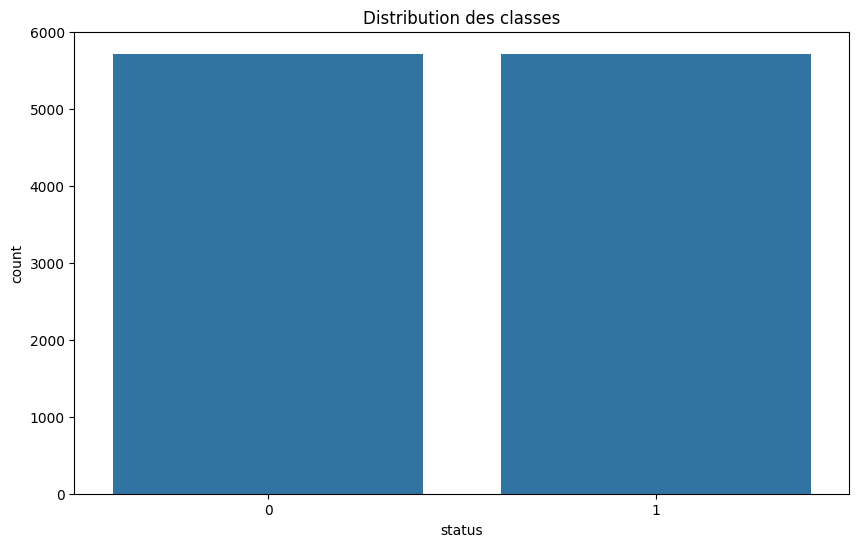

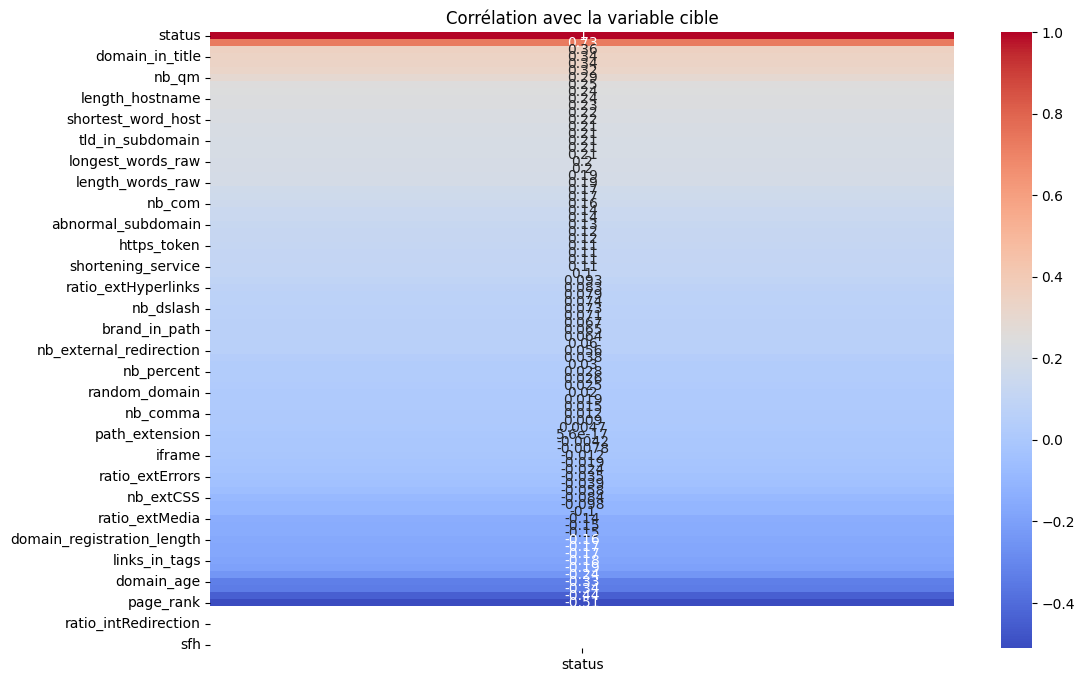

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Entraînement du modèle MLP...


MLP terminé.
Entraînement du modèle CNN...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


CNN terminé.
Entraînement du modèle LSTM...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


LSTM terminé.
Entraînement du modèle XGBoost...


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [22:02:16] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


XGBoost terminé.
Entraînement du modèle RandomForest...
RandomForest terminé.
286/286 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
286/286 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
286/286 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step
Méta-modèle entraîné.
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step

--- Rapport de classification (Stacking) ---
              precision    recall  f1-score   support

           0       0.97      0.96      0.97      1143
           1       0.96      0.97      0.97      1143

    accuracy                           0.97      2286
   macro avg       0.97      0.97      0.97      2286
weighted avg       0.97      0.97      0.97      2286



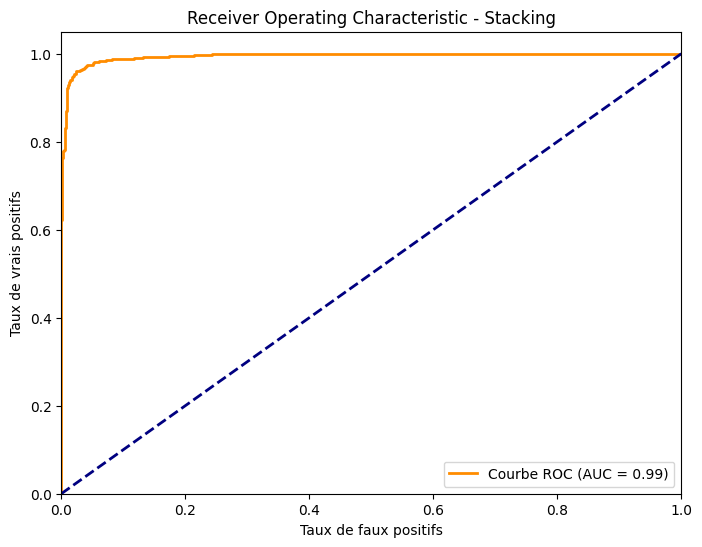

In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement et Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

# Modèles deep learning avec Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout, Conv1D, MaxPooling1D, Flatten, LSTM
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import tensorflow as tf

# Modèles scikit-learn et XGBoost
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

# Méta-modèle (stacking)
from sklearn.linear_model import LogisticRegression

# Chargement du dataset
df = pd.read_csv("dataset_phishing.csv")

# Préparation des données
df = df.drop(columns=['url'])  # Suppression de la colonne non pertinente
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})  # Encodage de la variable cible

# Visualisation exploratoire (optionnel)
plt.figure(figsize=(10, 6))
sns.countplot(x='status', data=df)
plt.title('Distribution des classes')
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr()[['status']].sort_values('status', ascending=False),
            annot=True, cmap='coolwarm')
plt.title('Corrélation avec la variable cible')
plt.show()

# Séparation des features et de la target
X = df.drop(columns=['status']).values
y = df['status'].values

# Normalisation des features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# Pour les modèles CNN et LSTM, on ajoute une dimension pour le canal
X_train_3d = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test_3d = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# -------------------------------------------------------
# Définition des modèles de base
# -------------------------------------------------------

# 1. Modèle MLP
def build_mlp(input_shape):
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_shape,)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

# 2. Modèle CNN
def build_cnn(input_shape):
    model = Sequential([
        Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=input_shape),
        MaxPooling1D(pool_size=2),
        BatchNormalization(),
        Dropout(0.3),
        Conv1D(filters=32, kernel_size=3, activation='relu'),
        MaxPooling1D(pool_size=2),
        BatchNormalization(),
        Dropout(0.3),
        Flatten(),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

# 3. Modèle LSTM
def build_lstm(input_shape):
    model = Sequential([
        LSTM(64, activation='tanh', return_sequences=True, input_shape=input_shape),
        Dropout(0.3),
        LSTM(32, activation='tanh'),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

# 4. Modèle XGBoost
xgb_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)

# 5. Modèle RandomForest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# -------------------------------------------------------
# Entraînement des modèles deep learning (MLP, CNN, LSTM)
# -------------------------------------------------------

# Paramètres d'entraînement communs
epochs = 100
batch_size = 64
callbacks = [
    EarlyStopping(patience=10, restore_best_weights=True),
    ModelCheckpoint('best_model.h5', save_best_only=True)
]

# Entraînement du MLP
mlp = build_mlp(X_train.shape[1])
print("Entraînement du modèle MLP...")
mlp.fit(X_train, y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.2,
        callbacks=callbacks,
        class_weight={0: 1, 1: 1.2},
        verbose=0)
print("MLP terminé.")

# Entraînement du CNN
cnn = build_cnn((X_train_3d.shape[1], X_train_3d.shape[2]))
print("Entraînement du modèle CNN...")
cnn.fit(X_train_3d, y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.2,
        callbacks=callbacks,
        class_weight={0: 1, 1: 1.2},
        verbose=0)
print("CNN terminé.")

# Entraînement du LSTM
lstm = build_lstm((X_train_3d.shape[1], X_train_3d.shape[2]))
print("Entraînement du modèle LSTM...")
lstm.fit(X_train_3d, y_train,
         epochs=epochs,
         batch_size=batch_size,
         validation_split=0.2,
         callbacks=callbacks,
         class_weight={0: 1, 1: 1.2},
         verbose=0)
print("LSTM terminé.")

# -------------------------------------------------------
# Entraînement des modèles scikit-learn (XGBoost, RandomForest)
# -------------------------------------------------------
print("Entraînement du modèle XGBoost...")
xgb_model.fit(X_train, y_train)
print("XGBoost terminé.")

print("Entraînement du modèle RandomForest...")
rf_model.fit(X_train, y_train)
print("RandomForest terminé.")

# -------------------------------------------------------
# Création des features pour le méta-modèle
# -------------------------------------------------------
# On récupère les probabilités prédites par chacun des modèles sur l'ensemble d'entraînement
# Pour les modèles deep learning, mlp.predict(X_train) renvoie des probabilités
meta_train_mlp   = mlp.predict(X_train)
meta_train_cnn   = cnn.predict(X_train_3d)
meta_train_lstm  = lstm.predict(X_train_3d)
meta_train_xgb   = xgb_model.predict_proba(X_train)[:, 1].reshape(-1, 1)
meta_train_rf    = rf_model.predict_proba(X_train)[:, 1].reshape(-1, 1)

# Concaténation des prédictions pour former le jeu de features du méta-modèle
meta_features_train = np.concatenate([meta_train_mlp, meta_train_cnn, meta_train_lstm,
                                        meta_train_xgb, meta_train_rf], axis=1)

# Création du méta-modèle (ici, une régression logistique)
meta_model = LogisticRegression()
meta_model.fit(meta_features_train, y_train)
print("Méta-modèle entraîné.")

# -------------------------------------------------------
# Prédictions sur l'ensemble de test
# -------------------------------------------------------
meta_test_mlp   = mlp.predict(X_test)
meta_test_cnn   = cnn.predict(X_test_3d)
meta_test_lstm  = lstm.predict(X_test_3d)
meta_test_xgb   = xgb_model.predict_proba(X_test)[:, 1].reshape(-1, 1)
meta_test_rf    = rf_model.predict_proba(X_test)[:, 1].reshape(-1, 1)

meta_features_test = np.concatenate([meta_test_mlp, meta_test_cnn, meta_test_lstm,
                                       meta_test_xgb, meta_test_rf], axis=1)

# Prédiction finale via le méta-modèle
y_pred_stack = meta_model.predict(meta_features_test)

# -------------------------------------------------------
# Évaluation des performances
# -------------------------------------------------------
print("\n--- Rapport de classification (Stacking) ---")
print(classification_report(y_test, y_pred_stack))

# Calcul de la courbe ROC pour le méta-modèle
proba_stack = meta_model.predict_proba(meta_features_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, proba_stack)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Courbe ROC (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Receiver Operating Characteristic - Stacking')
plt.legend(loc="lower right")
plt.show()


## apres osolation forest


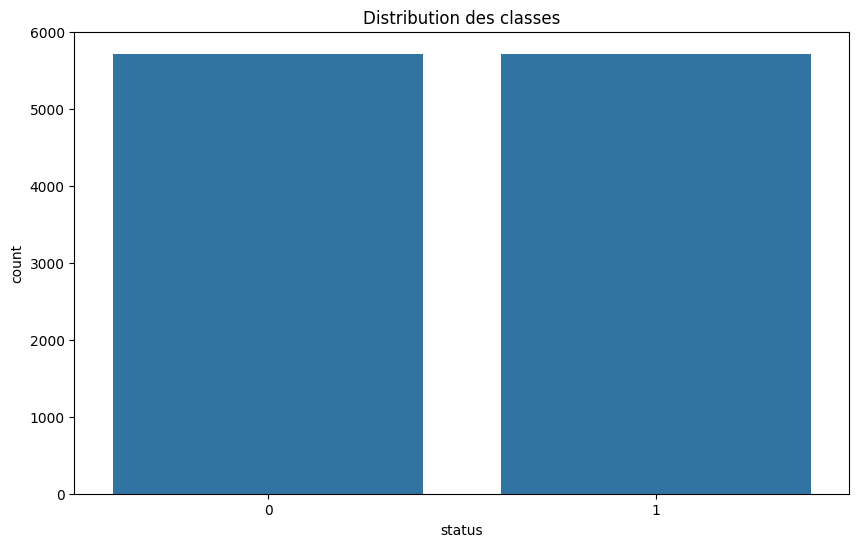

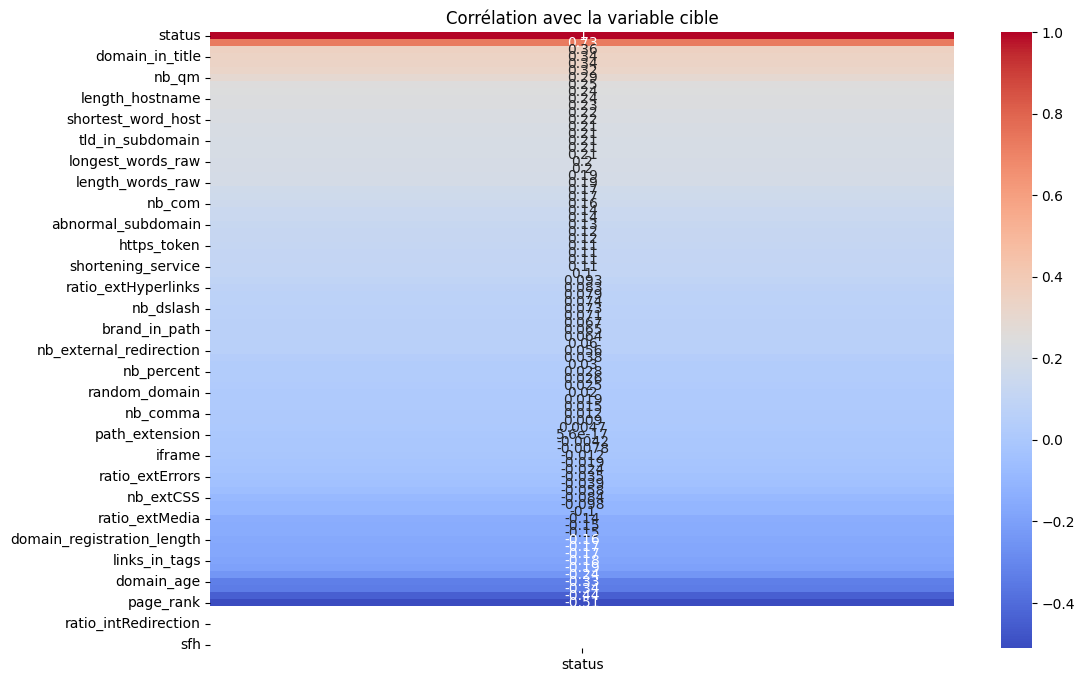

Nombre de points supprimés : 115
Distribution après équilibrage : [5709 5709]


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Entraînement du modèle MLP...


MLP terminé.
Entraînement du modèle CNN...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


CNN terminé.
Entraînement du modèle LSTM...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


LSTM terminé.
Entraînement du modèle XGBoost...


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [19:34:48] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


XGBoost terminé.
Entraînement du modèle RandomForest...
RandomForest terminé.
286/286 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
286/286 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
286/286 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step
Méta-modèle entraîné.
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step

--- Rapport de classification (Stacking) ---
              precision    recall  f1-score   support

           0       0.97      0.97      0.97      1142
           1       0.97      0.97      0.97      1142

    accuracy                           0.97      2284
   macro avg       0.97      0.97      0.97      2284
weighted avg       0.97      0.97      0.97      2284



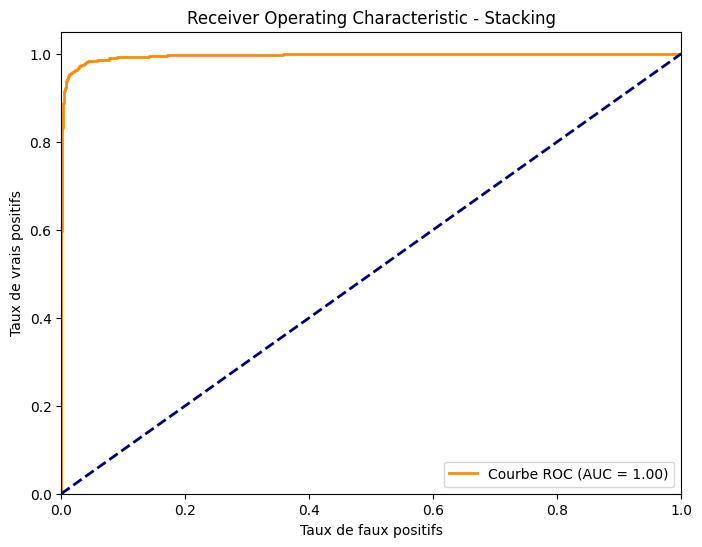

In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement et Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

# Modèles deep learning avec Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout, Conv1D, MaxPooling1D, Flatten, LSTM
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import tensorflow as tf

# Modèles scikit-learn et XGBoost
from sklearn.ensemble import RandomForestClassifier, IsolationForest
import xgboost as xgb

# Pour équilibrer la dataset
from imblearn.over_sampling import RandomOverSampler

# Méta-modèle (stacking)
from sklearn.linear_model import LogisticRegression

# Chargement du dataset
df = pd.read_csv("dataset_phishing.csv")

# Préparation des données
df = df.drop(columns=['url'])  # Suppression de la colonne non pertinente
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})  # Encodage de la variable cible

# Suppression des lignes dont la cible est NaN (au cas où)
df.dropna(subset=['status'], inplace=True)

# Visualisation exploratoire (optionnel)
plt.figure(figsize=(10, 6))
sns.countplot(x='status', data=df)
plt.title('Distribution des classes')
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr()[['status']].sort_values('status', ascending=False),
            annot=True, cmap='coolwarm')
plt.title('Corrélation avec la variable cible')
plt.show()

# Séparation des features et de la target
X = df.drop(columns=['status']).values
y = df['status'].values

# Normalisation des features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Suppression des anomalies avec IsolationForest
iso = IsolationForest(contamination=0.01, random_state=42)
pred_anomalies = iso.fit_predict(X)
mask = pred_anomalies != -1  # Conserve les échantillons jugés normaux
nombre_supprimes = len(X) - np.sum(mask)
print(f"Nombre de points supprimés : {nombre_supprimes}")

X = X[mask]
y = y[mask]

# Équilibrage de la dataset avec sur-échantillonnage
ros = RandomOverSampler(random_state=42)
X, y = ros.fit_resample(X, y)
print("Distribution après équilibrage :", np.bincount(y))

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# Pour les modèles CNN et LSTM, on ajoute une dimension pour le canal
X_train_3d = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test_3d = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# -------------------------------------------------------
# Définition des modèles de base
# -------------------------------------------------------

# 1. Modèle MLP
def build_mlp(input_shape):
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_shape,)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

# 2. Modèle CNN
def build_cnn(input_shape):
    model = Sequential([
        Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=input_shape),
        MaxPooling1D(pool_size=2),
        BatchNormalization(),
        Dropout(0.3),
        Conv1D(filters=32, kernel_size=3, activation='relu'),
        MaxPooling1D(pool_size=2),
        BatchNormalization(),
        Dropout(0.3),
        Flatten(),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

# 3. Modèle LSTM
def build_lstm(input_shape):
    model = Sequential([
        LSTM(64, activation='tanh', return_sequences=True, input_shape=input_shape),
        Dropout(0.3),
        LSTM(32, activation='tanh'),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

# 4. Modèle XGBoost
xgb_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)

# 5. Modèle RandomForest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# -------------------------------------------------------
# Entraînement des modèles deep learning (MLP, CNN, LSTM)
# -------------------------------------------------------

# Paramètres d'entraînement communs
epochs = 100
batch_size = 64
callbacks = [
    EarlyStopping(patience=10, restore_best_weights=True),
    ModelCheckpoint('best_model.h5', save_best_only=True)
]

# Entraînement du MLP
mlp = build_mlp(X_train.shape[1])
print("Entraînement du modèle MLP...")
mlp.fit(X_train, y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.2,
        callbacks=callbacks,
        class_weight={0: 1, 1: 1.2},
        verbose=0)
print("MLP terminé.")

# Entraînement du CNN
cnn = build_cnn((X_train_3d.shape[1], X_train_3d.shape[2]))
print("Entraînement du modèle CNN...")
cnn.fit(X_train_3d, y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.2,
        callbacks=callbacks,
        class_weight={0: 1, 1: 1.2},
        verbose=0)
print("CNN terminé.")

# Entraînement du LSTM
lstm = build_lstm((X_train_3d.shape[1], X_train_3d.shape[2]))
print("Entraînement du modèle LSTM...")
lstm.fit(X_train_3d, y_train,
         epochs=epochs,
         batch_size=batch_size,
         validation_split=0.2,
         callbacks=callbacks,
         class_weight={0: 1, 1: 1.2},
         verbose=0)
print("LSTM terminé.")

# -------------------------------------------------------
# Entraînement des modèles scikit-learn (XGBoost, RandomForest)
# -------------------------------------------------------
print("Entraînement du modèle XGBoost...")
xgb_model.fit(X_train, y_train)
print("XGBoost terminé.")

print("Entraînement du modèle RandomForest...")
rf_model.fit(X_train, y_train)
print("RandomForest terminé.")

# -------------------------------------------------------
# Création des features pour le méta-modèle
# -------------------------------------------------------
# On récupère les probabilités prédites par chacun des modèles sur l'ensemble d'entraînement
meta_train_mlp   = mlp.predict(X_train)
meta_train_cnn   = cnn.predict(X_train_3d)
meta_train_lstm  = lstm.predict(X_train_3d)
meta_train_xgb   = xgb_model.predict_proba(X_train)[:, 1].reshape(-1, 1)
meta_train_rf    = rf_model.predict_proba(X_train)[:, 1].reshape(-1, 1)

# Concaténation des prédictions pour former le jeu de features du méta-modèle
meta_features_train = np.concatenate([meta_train_mlp, meta_train_cnn, meta_train_lstm,
                                        meta_train_xgb, meta_train_rf], axis=1)

# Création du méta-modèle (ici, une régression logistique)
meta_model = LogisticRegression()
meta_model.fit(meta_features_train, y_train)
print("Méta-modèle entraîné.")

# -------------------------------------------------------
# Prédictions sur l'ensemble de test
# -------------------------------------------------------
meta_test_mlp   = mlp.predict(X_test)
meta_test_cnn   = cnn.predict(X_test_3d)
meta_test_lstm  = lstm.predict(X_test_3d)
meta_test_xgb   = xgb_model.predict_proba(X_test)[:, 1].reshape(-1, 1)
meta_test_rf    = rf_model.predict_proba(X_test)[:, 1].reshape(-1, 1)

meta_features_test = np.concatenate([meta_test_mlp, meta_test_cnn, meta_test_lstm,
                                       meta_test_xgb, meta_test_rf], axis=1)

# Prédiction finale via le méta-modèle
y_pred_stack = meta_model.predict(meta_features_test)

# -------------------------------------------------------
# Évaluation des performances
# -------------------------------------------------------
print("\n--- Rapport de classification (Stacking) ---")
print(classification_report(y_test, y_pred_stack))

# Calcul de la courbe ROC pour le méta-modèle
proba_stack = meta_model.predict_proba(meta_features_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, proba_stack)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Courbe ROC (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Receiver Operating Characteristic - Stacking')
plt.legend(loc="lower right")
plt.show()


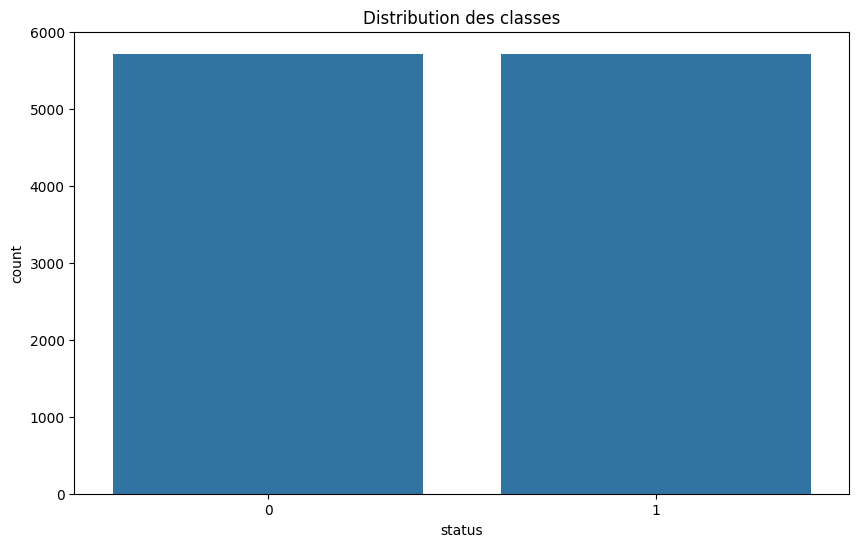

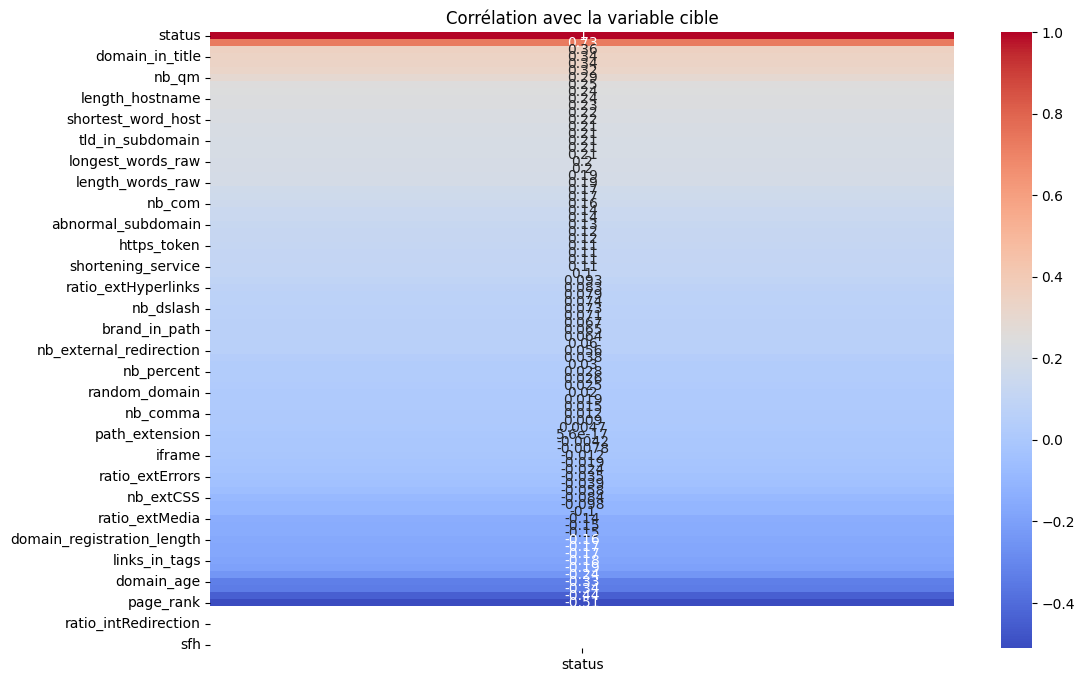

Nombre de points supprimés : 115
Distribution après équilibrage : [5709 5709]

Entraînement du modèle MLP 1/5...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Modèle 1 terminé.

Entraînement du modèle MLP 2/5...
Modèle 2 terminé.

Entraînement du modèle MLP 3/5...
Modèle 3 terminé.

Entraînement du modèle MLP 4/5...
Modèle 4 terminé.

Entraînement du modèle MLP 5/5...
Modèle 5 terminé.
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

--- Rapport de classification (Bagging - MLP) ---
              precision    recall  f1-score   support

           0       0.95      0.97      0.96      1142
           1       0.97      0.95      0.96      1142

    accuracy                           0.96      2284
   macro avg       0.96      0.96      0.96      2284
weighted avg       0.96      0.96      0.96      2284



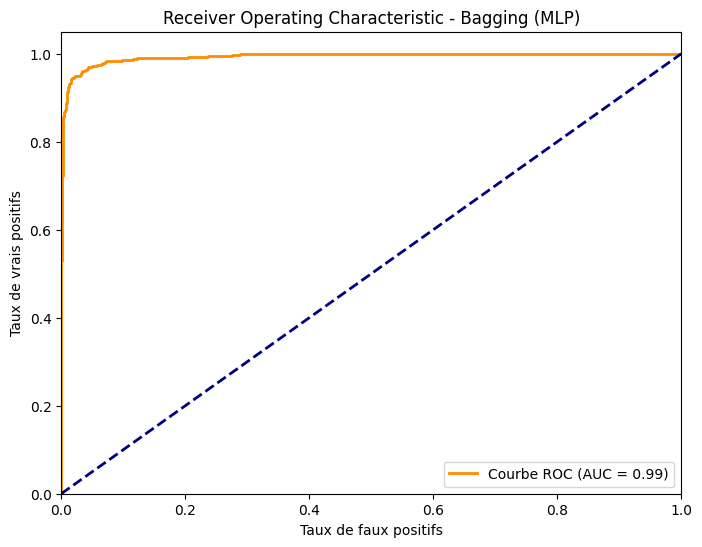

In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement et Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

# Modèles deep learning avec Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import tensorflow as tf

# Modèles scikit-learn et XGBoost
from sklearn.ensemble import IsolationForest
import xgboost as xgb

# Pour équilibrer la dataset
from imblearn.over_sampling import RandomOverSampler

# Méta-modèle (pour l'exemple précédent, ici nous utilisons le bagging pour un MLP)
from sklearn.linear_model import LogisticRegression

# Chargement du dataset
df = pd.read_csv("dataset_phishing.csv")

# Préparation des données
df = df.drop(columns=['url'])  # Suppression de la colonne non pertinente
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})  # Encodage de la variable cible

# Suppression des lignes avec des NaN dans 'status'
df.dropna(subset=['status'], inplace=True)

# Visualisation exploratoire (optionnel)
plt.figure(figsize=(10, 6))
sns.countplot(x='status', data=df)
plt.title('Distribution des classes')
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr()[['status']].sort_values('status', ascending=False),
            annot=True, cmap='coolwarm')
plt.title('Corrélation avec la variable cible')
plt.show()

# Séparation des features et de la target
X = df.drop(columns=['status']).values
y = df['status'].values

# Normalisation des features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Suppression des anomalies avec IsolationForest
iso = IsolationForest(contamination=0.01, random_state=42)
pred_anomalies = iso.fit_predict(X)
mask = pred_anomalies != -1  # Conserve les échantillons jugés normaux
nombre_supprimes = len(X) - np.sum(mask)
print(f"Nombre de points supprimés : {nombre_supprimes}")

X = X[mask]
y = y[mask]

# Équilibrage de la dataset avec sur-échantillonnage
ros = RandomOverSampler(random_state=42)
X, y = ros.fit_resample(X, y)
print("Distribution après équilibrage :", np.bincount(y))

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# -------------------------------------------------------
# Définition du modèle de base (MLP)
# -------------------------------------------------------
def build_mlp(input_shape):
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_shape,)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

# -------------------------------------------------------
# Mise en place du Bagging pour le modèle MLP
# -------------------------------------------------------
import random

n_estimators = 5         # Nombre de modèles dans l'ensemble
epochs = 100
batch_size = 64

bagging_models = []      # Liste pour stocker les modèles
callbacks = [
    EarlyStopping(patience=10, restore_best_weights=True),
    ModelCheckpoint('best_model.h5', save_best_only=True)
]

# Entraînement de chaque modèle sur un bootstrap (échantillonnage avec remplacement)
for i in range(n_estimators):
    print(f"\nEntraînement du modèle MLP {i+1}/{n_estimators}...")
    # Création d'un échantillon bootstrap
    indices = np.random.choice(np.arange(len(X_train)), size=len(X_train), replace=True)
    X_train_boot = X_train[indices]
    y_train_boot = y_train[indices]

    # Construction et entraînement du modèle
    model = build_mlp(X_train.shape[1])
    model.fit(X_train_boot, y_train_boot,
              epochs=epochs,
              batch_size=batch_size,
              validation_split=0.2,
              callbacks=callbacks,
              class_weight={0: 1, 1: 1.2},
              verbose=0)
    bagging_models.append(model)
    print(f"Modèle {i+1} terminé.")

# -------------------------------------------------------
# Agrégation des prédictions (vote majoritaire via moyenne des probabilités)
# -------------------------------------------------------
# Prédiction pour chaque modèle sur l'ensemble de test
predictions = []
for model in bagging_models:
    pred = model.predict(X_test)
    predictions.append(pred)

# Convertir la liste en tableau et calculer la moyenne
predictions = np.array(predictions)  # forme: (n_estimators, n_samples, 1)
avg_predictions = np.mean(predictions, axis=0)

# Appliquer un seuil de 0.5 pour obtenir la classe finale
y_pred_bagging = (avg_predictions >= 0.5).astype(int).ravel()

# Évaluation des performances
print("\n--- Rapport de classification (Bagging - MLP) ---")
print(classification_report(y_test, y_pred_bagging))

# Calcul de la courbe ROC pour le bagging
proba_bagging = avg_predictions.ravel()
fpr, tpr, thresholds = roc_curve(y_test, proba_bagging)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Courbe ROC (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Receiver Operating Characteristic - Bagging (MLP)')
plt.legend(loc="lower right")
plt.show()


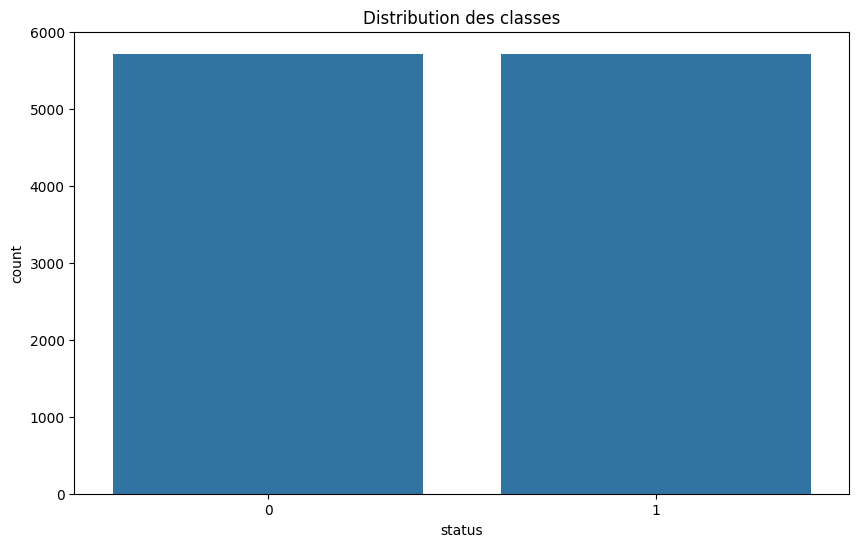

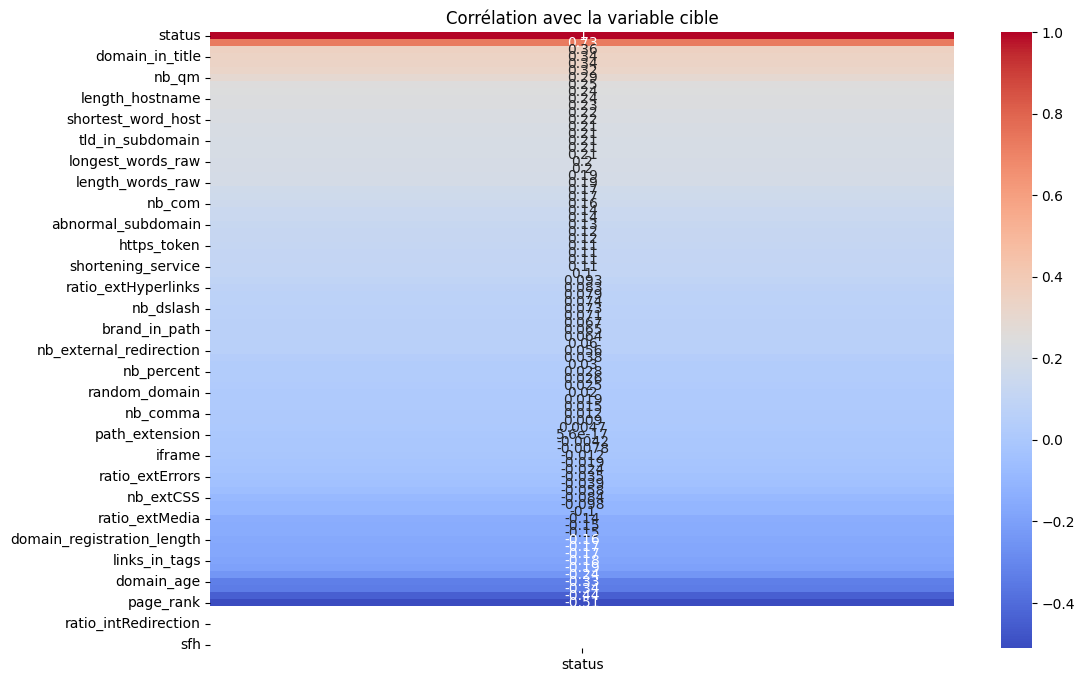

Pour une contamination de 0.005, points supprimés : 58
Pour une contamination de 0.01, points supprimés : 115
Pour une contamination de 0.02, points supprimés : 229
Distribution après SMOTE : [5709 5709]

=== Entraînement avec 3 estimateurs ===

Entraînement du modèle MLP 1/3...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Modèle 1 terminé.

Entraînement du modèle MLP 2/3...


Modèle 2 terminé.

Entraînement du modèle MLP 3/3...


Modèle 3 terminé.
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

--- Rapport de classification ---
              precision    recall  f1-score   support

           0       0.96      0.97      0.96      1142
           1       0.97      0.95      0.96      1142

    accuracy                           0.96      2284
   macro avg       0.96      0.96      0.96      2284
weighted avg       0.96      0.96      0.96      2284



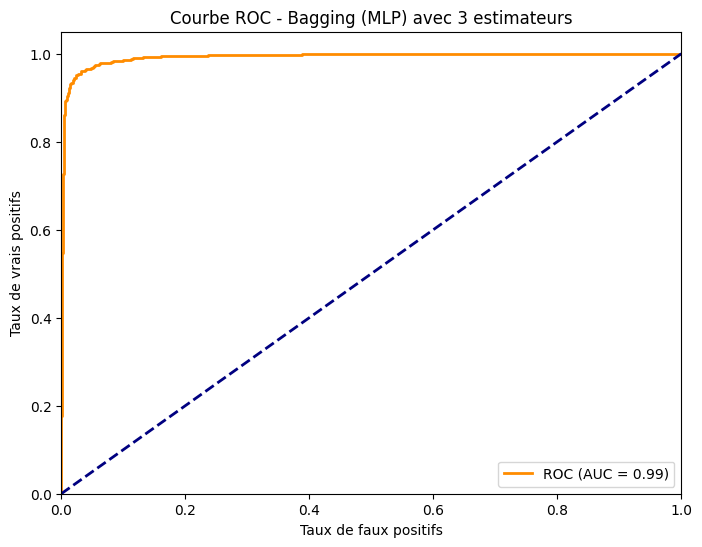


=== Entraînement avec 5 estimateurs ===

Entraînement du modèle MLP 1/5...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Modèle 1 terminé.

Entraînement du modèle MLP 2/5...
Modèle 2 terminé.

Entraînement du modèle MLP 3/5...
Modèle 3 terminé.

Entraînement du modèle MLP 4/5...
Modèle 4 terminé.

Entraînement du modèle MLP 5/5...
Modèle 5 terminé.
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

--- Rapport de classification ---
              precision    recall  f1-score   support

           0       0.96      0.97      0.96      1142
           1       0.97      0.96      0.96      1142

    accuracy                           0.96      2284
   macro avg       0.96      0.96      0.96      2284
weighted avg       0.96      0.96      0.96      2284



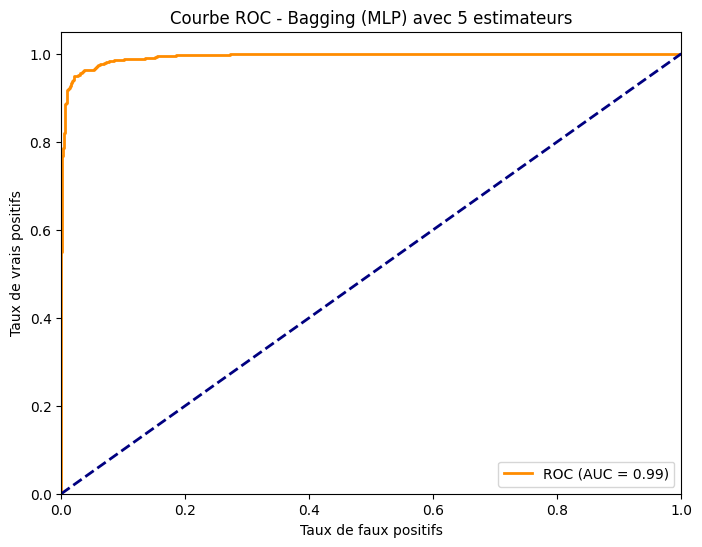


=== Entraînement avec 7 estimateurs ===

Entraînement du modèle MLP 1/7...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Modèle 1 terminé.

Entraînement du modèle MLP 2/7...
Modèle 2 terminé.

Entraînement du modèle MLP 3/7...
Modèle 3 terminé.

Entraînement du modèle MLP 4/7...


Modèle 4 terminé.

Entraînement du modèle MLP 5/7...


Modèle 5 terminé.

Entraînement du modèle MLP 6/7...
Modèle 6 terminé.

Entraînement du modèle MLP 7/7...
Modèle 7 terminé.
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

--- Rapport de classification ---
              precision    recall  f1-score   support

           0       0.96      0.98      0.97      1142
           1       0.97      0.96      0.97      1142

    accuracy                           0.97      2284
   macro avg       0.97      0.97      0.97      2284
weighted avg       0.97      0.97      0.97      2284



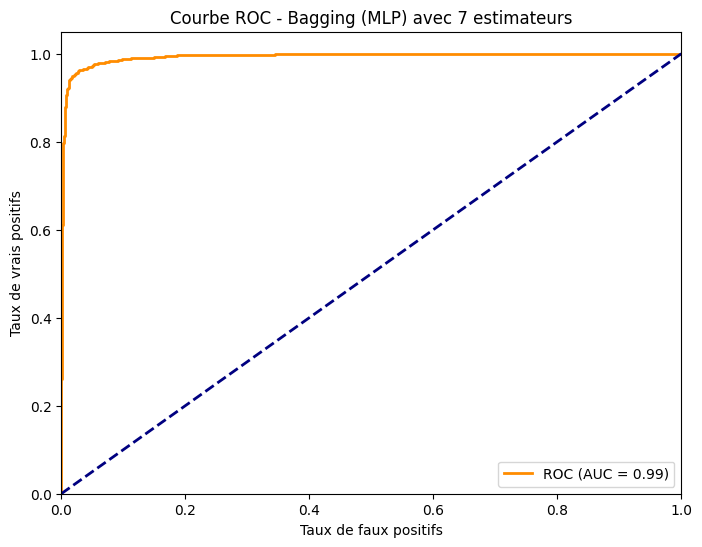


=== Entraînement avec 10 estimateurs ===

Entraînement du modèle MLP 1/10...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Modèle 1 terminé.

Entraînement du modèle MLP 2/10...
Modèle 2 terminé.

Entraînement du modèle MLP 3/10...
Modèle 3 terminé.

Entraînement du modèle MLP 4/10...
Modèle 4 terminé.

Entraînement du modèle MLP 5/10...
Modèle 5 terminé.

Entraînement du modèle MLP 6/10...
Modèle 6 terminé.

Entraînement du modèle MLP 7/10...
Modèle 7 terminé.

Entraînement du modèle MLP 8/10...
Modèle 8 terminé.

Entraînement du modèle MLP 9/10...
Modèle 9 terminé.

Entraînement du modèle MLP 10/10...
Modèle 10 terminé.
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

--- Rapport de classification ---
              precision    recall  f1-score   support

           0  

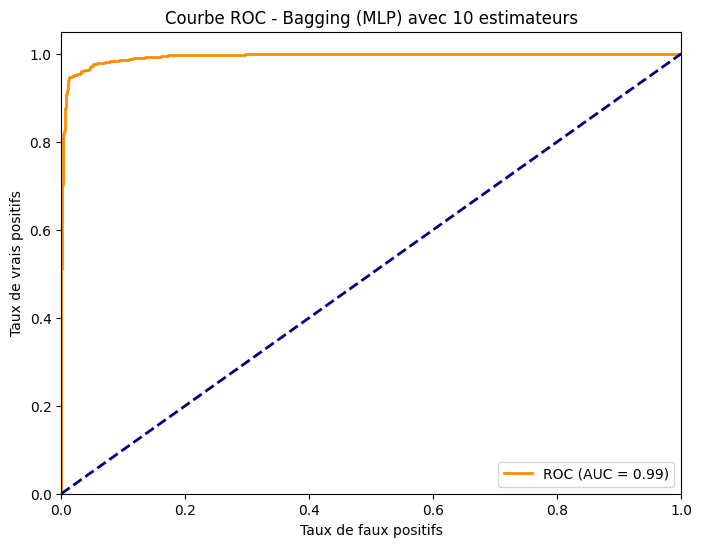

In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement et Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

# Modèles deep learning avec Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import tensorflow as tf

# Détection d'anomalies
from sklearn.ensemble import IsolationForest

# Pour équilibrer la dataset avec SMOTE
from imblearn.over_sampling import SMOTE

# Pour le Bagging
import random

# Chargement du dataset
df = pd.read_csv("dataset_phishing.csv")

# Préparation des données
df = df.drop(columns=['url'])  # Suppression de la colonne non pertinente
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})  # Encodage de la variable cible

# Suppression des lignes avec des NaN dans 'status'
df.dropna(subset=['status'], inplace=True)

# Visualisation exploratoire (optionnel)
plt.figure(figsize=(10, 6))
sns.countplot(x='status', data=df)
plt.title('Distribution des classes')
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr()[['status']].sort_values('status', ascending=False),
            annot=True, cmap='coolwarm')
plt.title('Corrélation avec la variable cible')
plt.show()

# Séparation des features et de la target
X = df.drop(columns=['status']).values
y = df['status'].values

# Normalisation des features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# ---------------------------
# 1. Suppression des anomalies
# ---------------------------
# Essai de différents niveaux de contamination pour IsolationForest
for contamination in [0.005, 0.01, 0.02]:
    iso = IsolationForest(contamination=contamination, random_state=42)
    pred_anomalies = iso.fit_predict(X)
    mask = pred_anomalies != -1
    nombre_supprimes = len(X) - np.sum(mask)
    print(f"Pour une contamination de {contamination}, points supprimés : {nombre_supprimes}")

# Choix du taux de contamination (par exemple 1%)
chosen_contamination = 0.01
iso = IsolationForest(contamination=chosen_contamination, random_state=42)
pred_anomalies = iso.fit_predict(X)
mask = pred_anomalies != -1  # Conserve les échantillons jugés normaux
X = X[mask]
y = y[mask]

# ---------------------------
# 2. Équilibrage de la dataset avec SMOTE
# ---------------------------
smote = SMOTE(random_state=42)
X, y = smote.fit_resample(X, y)
print("Distribution après SMOTE :", np.bincount(y))

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# ---------------------------
# 3. Définition du modèle MLP
# ---------------------------
def build_mlp(input_shape):
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_shape,)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

# ---------------------------
# 4. Fonction d'entraînement du Bagging
# ---------------------------
epochs = 100
batch_size = 64

callbacks = [
    EarlyStopping(patience=10, restore_best_weights=True),
    ModelCheckpoint('best_model.h5', save_best_only=True)
]

def train_bagging_model(n_estimators, X_train, y_train):
    bagging_models = []
    for i in range(n_estimators):
        print(f"\nEntraînement du modèle MLP {i+1}/{n_estimators}...")
        # Création d'un échantillon bootstrap
        indices = np.random.choice(np.arange(len(X_train)), size=len(X_train), replace=True)
        X_train_boot = X_train[indices]
        y_train_boot = y_train[indices]

        model = build_mlp(X_train.shape[1])
        model.fit(X_train_boot, y_train_boot,
                  epochs=epochs,
                  batch_size=batch_size,
                  validation_split=0.2,
                  callbacks=callbacks,
                  class_weight={0: 1, 1: 1.2},
                  verbose=0)
        bagging_models.append(model)
        print(f"Modèle {i+1} terminé.")
    return bagging_models

# ---------------------------
# 5. Expérimentation avec différents nombres d'estimateurs
# ---------------------------
# Vous pouvez expérimenter avec plusieurs valeurs
for n in [3, 5, 7, 10]:
    print(f"\n=== Entraînement avec {n} estimateurs ===")
    bagging_models = train_bagging_model(n, X_train, y_train)

    # Agrégation des prédictions sur l'ensemble de test
    predictions = []
    for model in bagging_models:
        pred = model.predict(X_test)
        predictions.append(pred)

    # Calcul de la moyenne des prédictions
    predictions = np.array(predictions)  # forme: (n_estimators, n_samples, 1)
    avg_predictions = np.mean(predictions, axis=0)

    # Application du seuil 0.5 pour obtenir la classe finale
    y_pred = (avg_predictions >= 0.5).astype(int).ravel()

    # Évaluation des performances
    print("\n--- Rapport de classification ---")
    print(classification_report(y_test, y_pred))

    # Calcul et affichage de la courbe ROC
    proba = avg_predictions.ravel()
    fpr, tpr, thresholds = roc_curve(y_test, proba)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC (AUC = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Taux de faux positifs')
    plt.ylabel('Taux de vrais positifs')
    plt.title(f'Courbe ROC - Bagging (MLP) avec {n} estimateurs')
    plt.legend(loc="lower right")
    plt.show()


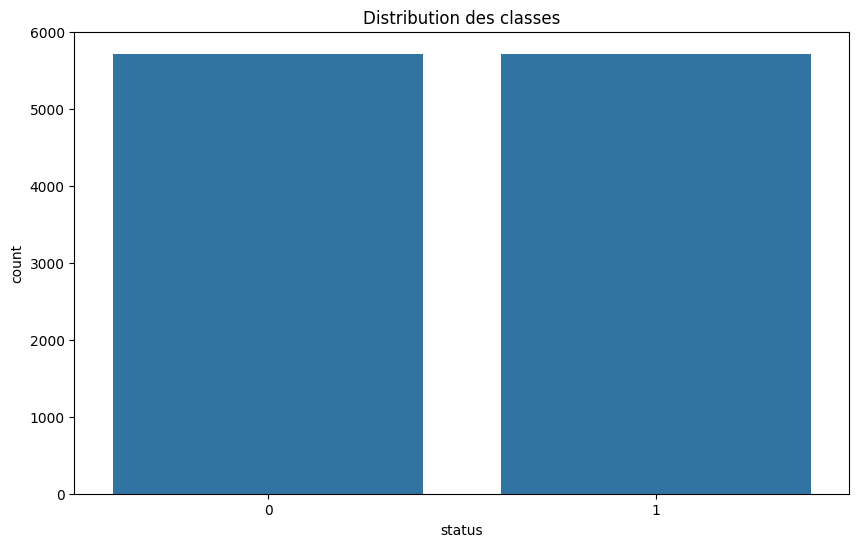

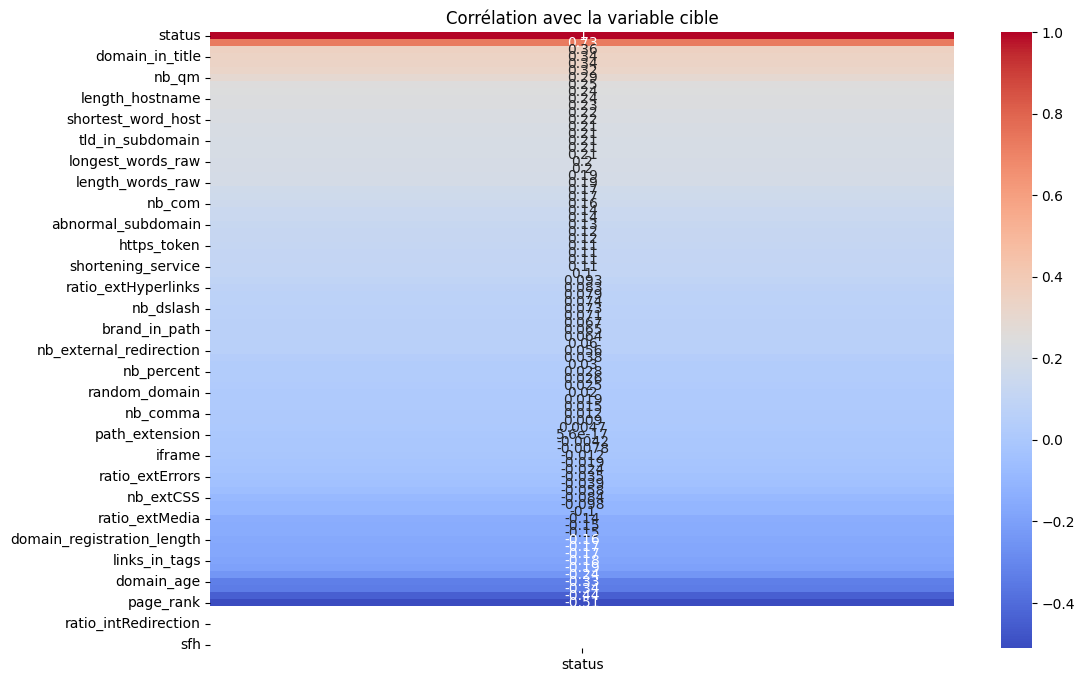

Nombre de points supprimés : 115
Distribution après équilibrage : [5709 5709]

--- Rapport de classification (Stacking) ---
              precision    recall  f1-score   support

           0       0.97      0.97      0.97      1142
           1       0.97      0.97      0.97      1142

    accuracy                           0.97      2284
   macro avg       0.97      0.97      0.97      2284
weighted avg       0.97      0.97      0.97      2284



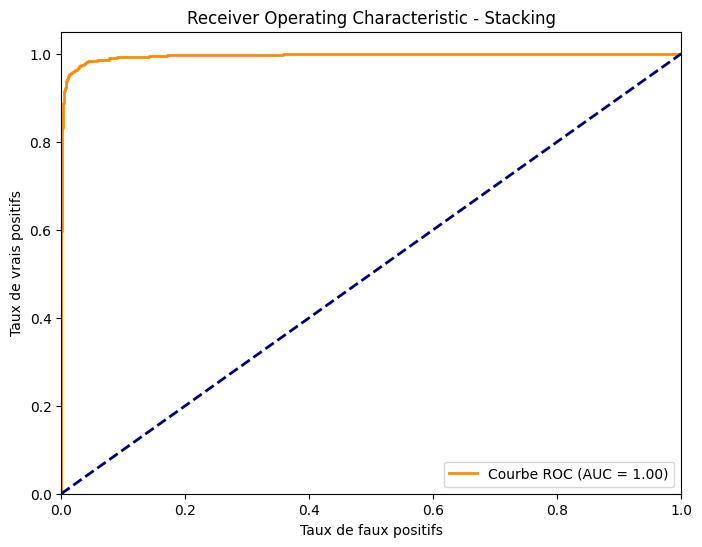

In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement et Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

# Modèles deep learning avec Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout, Conv1D, MaxPooling1D, Flatten, LSTM
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import tensorflow as tf

# Modèles scikit-learn et XGBoost
from sklearn.ensemble import RandomForestClassifier, IsolationForest
import xgboost as xgb

# Pour équilibrer la dataset
from imblearn.over_sampling import RandomOverSampler

# Méta-modèle (stacking)
from sklearn.linear_model import LogisticRegression

# Chargement du dataset
df = pd.read_csv("dataset_phishing.csv")

# Préparation des données
df = df.drop(columns=['url'])  # Suppression de la colonne non pertinente
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})  # Encodage de la variable cible

# Suppression des lignes dont la cible est NaN (au cas où)
df.dropna(subset=['status'], inplace=True)

# Visualisation exploratoire (optionnel)
plt.figure(figsize=(10, 6))
sns.countplot(x='status', data=df)
plt.title('Distribution des classes')
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr()[['status']].sort_values('status', ascending=False),
            annot=True, cmap='coolwarm')
plt.title('Corrélation avec la variable cible')
plt.show()

# Séparation des features et de la target
X = df.drop(columns=['status']).values
y = df['status'].values

# Normalisation des features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Suppression des anomalies avec IsolationForest
iso = IsolationForest(contamination=0.01, random_state=42)
pred_anomalies = iso.fit_predict(X)
mask = pred_anomalies != -1  # Conserve les échantillons jugés normaux
nombre_supprimes = len(X) - np.sum(mask)
print(f"Nombre de points supprimés : {nombre_supprimes}")

X = X[mask]
y = y[mask]

# Équilibrage de la dataset avec sur-échantillonnage
ros = RandomOverSampler(random_state=42)
X, y = ros.fit_resample(X, y)
print("Distribution après équilibrage :", np.bincount(y))

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# Pour les modèles CNN et LSTM, on ajoute une dimension pour le canal
X_train_3d = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test_3d = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# Définition des modèles de base
def build_mlp(input_shape):
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_shape,)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

def build_cnn(input_shape):
    model = Sequential([
        Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=input_shape),
        MaxPooling1D(pool_size=2),
        BatchNormalization(),
        Dropout(0.3),
        Conv1D(filters=32, kernel_size=3, activation='relu'),
        MaxPooling1D(pool_size=2),
        BatchNormalization(),
        Dropout(0.3),
        Flatten(),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

def build_lstm(input_shape):
    model = Sequential([
        LSTM(64, activation='tanh', return_sequences=True, input_shape=input_shape),
        Dropout(0.3),
        LSTM(32, activation='tanh'),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

xgb_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Entraînement et prédictions des modèles...
# (Code inchangé pour la suite)

# Évaluation des performances
print("\n--- Rapport de classification (Stacking) ---")
print(classification_report(y_test, y_pred_stack))

proba_stack = meta_model.predict_proba(meta_features_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, proba_stack)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Courbe ROC (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Receiver Operating Characteristic - Stacking')
plt.legend(loc="lower right")
plt.show()
